# **Indian Union Budget 2024-2025 Analysis**




## 📖 1. Motive / Backstory
The **Union Budget of India** is the most highly anticipated economic event of the year. Delivered by the Hon'ble Finance Minister in the Parliament, this comprehensive speech doesn't just allocate funds—it sets the economic narrative, defines the government's priorities, and influences market sentiment for the entire fiscal year. 

However, a 30 to 40-page technical speech can be overwhelming to digest manually. While news channels provide summarized highlights, the raw, authentic tone and granular focus of the government often get lost in media interpretation. As data enthusiasts, we can leverage **Natural Language Processing (NLP)** to bypass the noise, directly analyze the authentic Parliamentary text, and let the data reveal the true focus of the budget.

---

## 🎯 2. Problem Statement
**Objective:** To systematically analyze the latest Union Budget Speech of India using Natural Language Processing (NLP) to extract underlying sentiments, dominant themes, and key sector priorities.

**Specific Goals of this Project:**
1. **Automated Extraction:** Fetch and parse the authentic budget speech document directly from the official India Budget portal.
2. **Text Processing (Cleaning):** Standardize the raw text by removing stop words, legal jargon, and punctuations to prepare a clean corpus.
3. **Thematic EDA:** Identify the most frequently emphasized words and sectors (e.g., Agriculture, Technology, Defense) to visualize the government's core focus areas using WordClouds and Frequency Plots.
4. **Sentiment & Tone Analysis:** Apply sentiment analysis to understand the emotional trajectory of the speech—identifying whether the overall tone is optimistic (growth-oriented), neutral (factual allocations), or cautious (focusing on inflation/deficits).

### **Library Importation**

In [1]:
import numpy as np
import pandas as pd
import requests
import os
import pypdf
import seaborn as sns
import nltk
import string
import ollama
import matplotlib.pyplot as plt
from google import genai
from google.genai import types
from docx import Document
from wordcloud import WordCloud
from textblob import TextBlob
from nltk.util import ngrams
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from collections import Counter
from scipy import stats
from dotenv import load_dotenv
from groq import Groq

import warnings
warnings.filterwarnings("ignore")


In [2]:
import nltk
import ssl


try:
    _create_unverified_https_context = ssl._create_unverified_context
except AttributeError:
    pass
else:
    ssl._create_default_https_context = _create_unverified_https_context

nltk.download('punkt')
nltk.download('punkt_tab') 
nltk.download('stopwords')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\AVIRAL\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\AVIRAL\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\AVIRAL\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [6]:

url = "https://www.indiabudget.gov.in/doc/bspeech/bs2024_25.pdf"
file_name = "Budget_Speech_2024-25.pdf"

headers = {"User-Agent": "Mozilla/5.0"}
res = requests.get(url, headers=headers)

if res.status_code == 200:
    with open(file_name, "wb") as f:
        f.write(res.content)
    print("Downloaded.")
else:
    print(f"Fetch failed: {res.status_code}")

li = []
if os.path.exists(file_name):
    reader = pypdf.PdfReader(file_name)
    for page in reader.pages:
        text = page.extract_text()
        if text:
            paras = [p.strip() for p in text.split('\n') if len(p.strip()) > 30]
            li.extend(paras)

    print(f"Extracted {len(li)} paragraphs.")
else:
    print("File missing.")

Downloaded.
Extracted 1310 paragraphs.


In [7]:
import pypdf

# PDF read karne ke liye
reader = pypdf.PdfReader(file_name)
li = []

for page in reader.pages:
    text = page.extract_text()
    if text:
        # Paragraphs ko break karke clean text nikaalna
        for p in text.split("\n"):
            p = p.strip()
            if len(p) > 25:  # chhote headers/page numbers filter karne ke liye
                li.append(p)

print(f"\n✅ Extraction Complete! The speech contains {len(li)} paragraphs.")
print("\n--- Initial Look at Data ---")
print(li[:2])


✅ Extraction Complete! The speech contains 1398 paragraphs.

--- Initial Look at Data ---
['(i) Productivity and resilience in Agriculture', '(ii) Employment & Skilling']


In [12]:
stop_words = set(stopwords.words("english"))


custom_stop_words = stop_words.union({'crore', 'lakh', 'rupees', 'lakhs', "proposed", "provide", "scheme", 
                                      'crores', 'government', 'year', 'also', 'budget', 'per', 'cent', 'rs', 'percent', "rate", "madam", "speaker", "honble"})


def clean_text(text):
    text = text.lower()
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = ''.join([i for i in text if not i.isdigit()])
    

    y = word_tokenize(text)

    cleaned_text = [w for w in y if w not in custom_stop_words and len(w) > 2]

    return " ".join(cleaned_text)


clean_paras = [clean_text(q) for q in li]

full_cleaned_Speech = " ".join(clean_paras)


print("Data Cleaning Completed")

print("Cleaned preview:", clean_paras[10][:100],"....")

Data Cleaning Completed
Cleaned preview: third term leadership grateful support faith ....


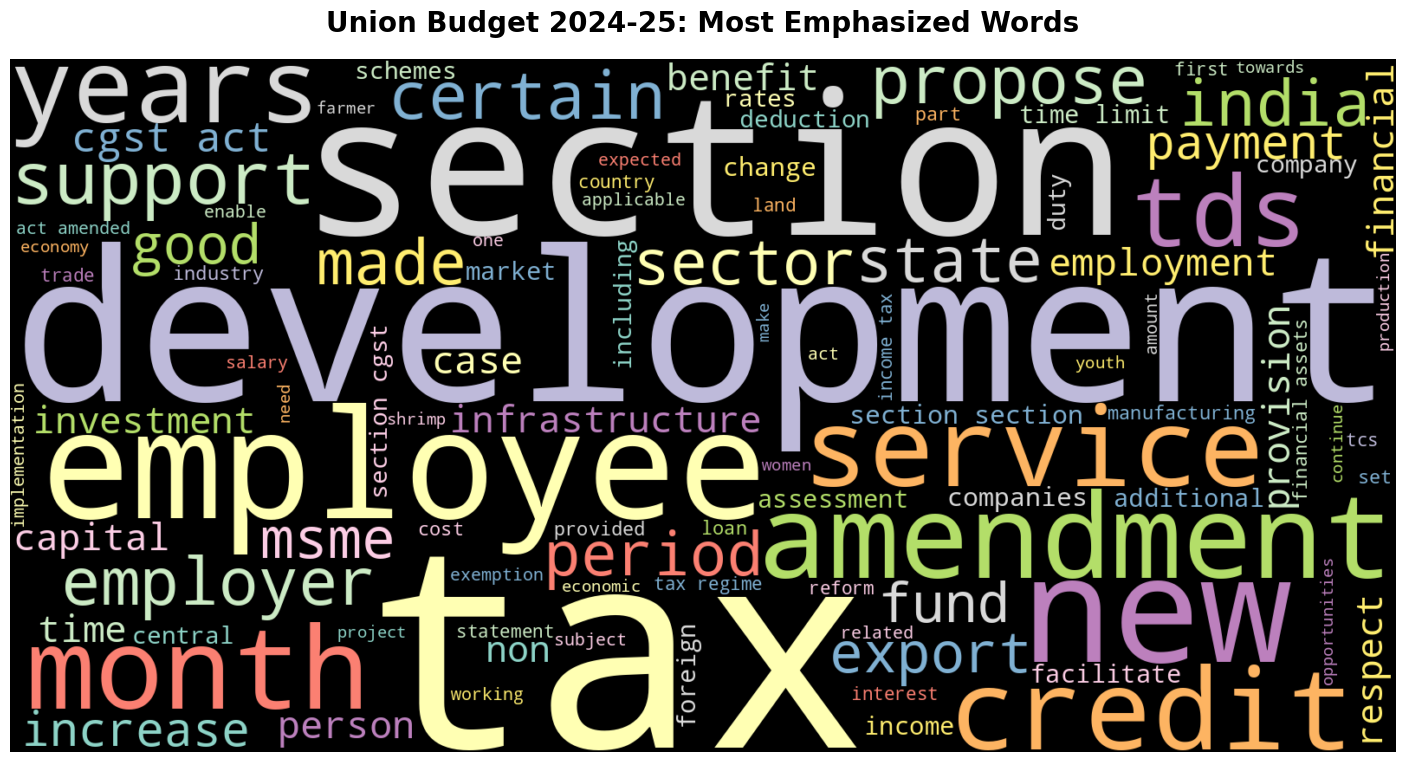

In [13]:
plt.figure(figsize=(18,9))
cloud = WordCloud(width=1600,height=800,background_color="black", colormap='Set3', max_words=101).generate(full_cleaned_Speech)
plt.imshow(cloud, interpolation="bilinear")
plt.axis("off")
plt.title("Union Budget 2024-25: Most Emphasized Words", fontsize=20, fontweight='bold', pad=20)
plt.show()

In [14]:
ls = full_cleaned_Speech.split()
cnt = Counter(ls)
top10 = cnt.most_common(10)

df = pd.DataFrame(top10, columns=['Word', 'Frequency'])
df

,Word,Frequency
0,tax,95
1,section,81
2,development,50
3,act,48
4,years,46
5,financial,38
6,new,33
7,support,31
8,time,31
9,propose,31


In [15]:
bigrams = ngrams(ls,2)
bigrams_freq = Counter(bigrams)


top10_bigrams = bigrams_freq.most_common(10)
bigrams_data = {"Bigrams" : [f"{q[0][0]} {q[0][1]}" for q in top10_bigrams],
                "Count" : [q[1] for q in top10_bigrams]}


df_bigrams = pd.DataFrame(bigrams_data)
df_bigrams

,Bigrams,Count
0,cgst act,19
1,section section,15
2,section cgst,14
3,time limit,13
4,financial assets,13
5,income tax,12
6,tax regime,11
7,act amended,11
8,capital gains,9
9,five years,8


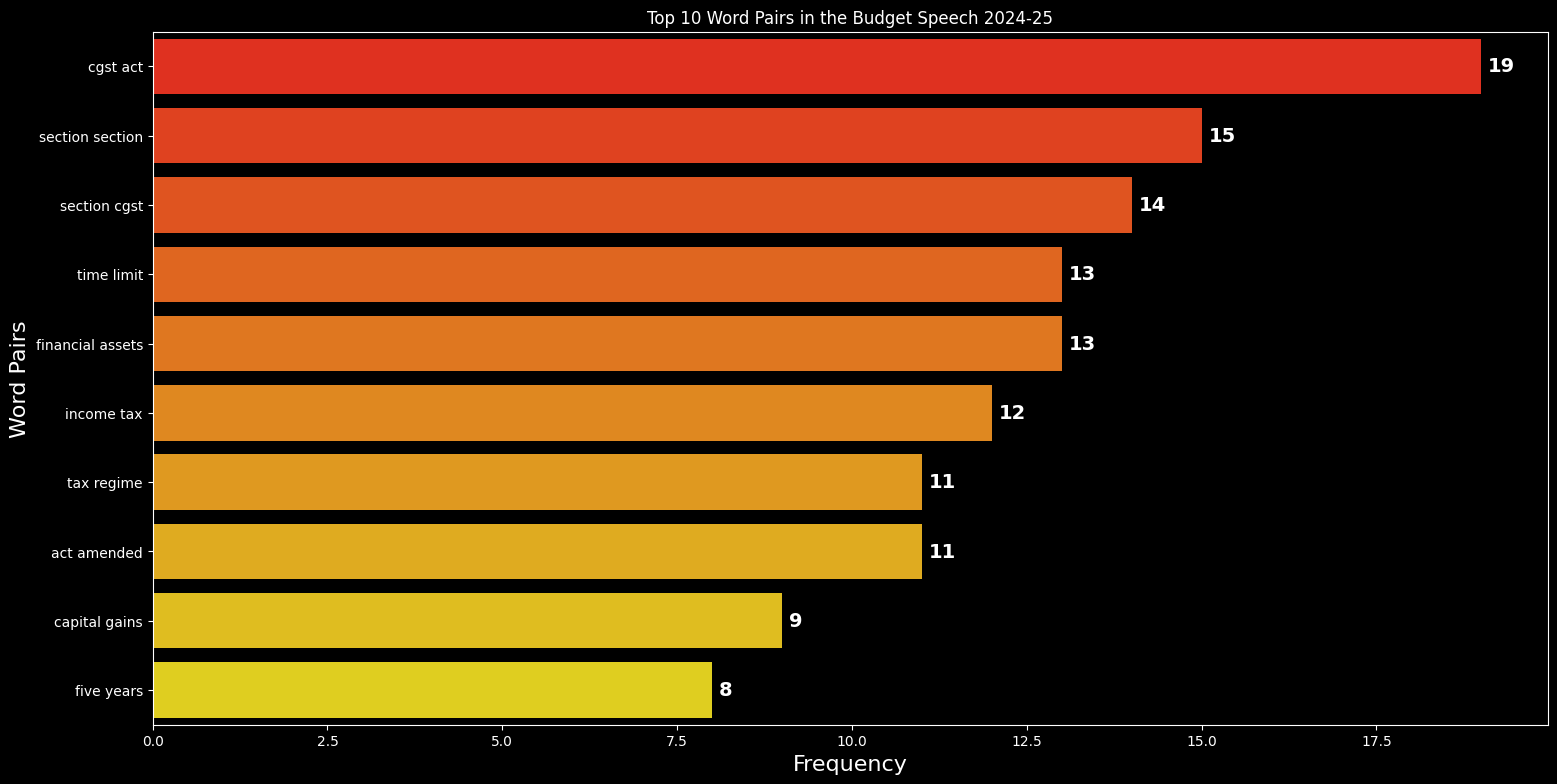

In [16]:
plt.style.use("dark_background") 

plt.figure(figsize=(18,9))
bar = sns.barplot(x="Count", y="Bigrams", data=df_bigrams, palette="autumn")

for i in bar.containers:

    bar.bar_label(i, padding=5, color='white', fontsize=14, fontweight='bold')

plt.title('Top 10 Word Pairs in the Budget Speech 2024-25')
plt.xlabel("Frequency", fontsize=16)
plt.ylabel("Word Pairs", fontsize=16)
plt.show()

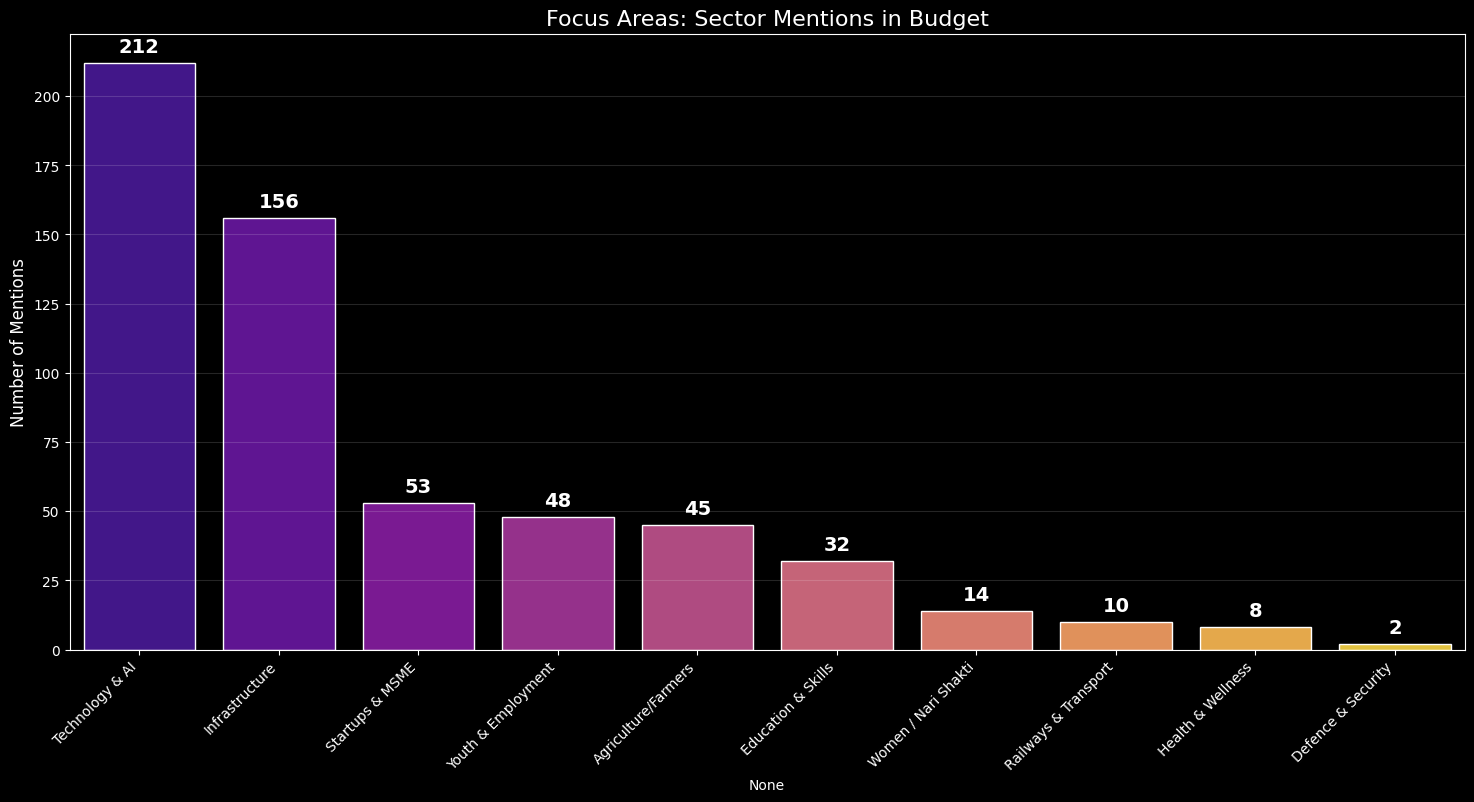

In [17]:
sec = {
    'Agriculture/Farmers': ['agriculture', 'farmer', 'farmers', 'kisan', 'crop', 'crops', 'rural', 'irrigation'],
    'Education & Skills': ['education', 'school', 'schools', 'college', 'university', 'students', 'learning', 'skill', 'skills'],
    'Health & Wellness': ['health', 'hospital', 'hospitals', 'medical', 'disease', 'vaccine', 'nutrition', 'ayushman'],
    'Railways & Transport': ['rail', 'railway', 'railways', 'train', 'trains', 'vande bharat', 'station', 'metro'],
    'Technology & AI': ['technology', 'digital', 'tech', 'ai', 'innovation', 'artificial intelligence', 'research'],
    'Defence & Security': ['defence', 'military', 'army', 'navy', 'airforce', 'armed forces', 'border'],
    'Women / Nari Shakti': ['women', 'woman', 'girl', 'girls', 'nari', 'shakti', 'mahila', 'matru'],
    'Youth & Employment': ['youth', 'young', 'employment', 'jobs', 'job', 'rozgar', 'career'],
    'Startups & MSME': ['startup', 'startups', 'msme', 'msmes', 'entrepreneur', 'entrepreneurship', 'business', 'businesses'],
    'Infrastructure': ['infrastructure', 'infra', 'roads', 'highway', 'highways', 'bridge', 'bridges', 'port', 'ports', 'aviation']
}

dict = {}

for sector_name, word_list in sec.items():
    total = 0
    for word in word_list:
        total += full_cleaned_Speech.count(word)
    dict[sector_name] = total

df_sec = pd.Series(dict).sort_values(ascending=False)

plt.figure(figsize=(18,8))
ax = sns.barplot(x=df_sec.index, y=df_sec.values, palette='plasma', edgecolor="white")

for container in ax.containers:
    ax.bar_label(container, padding=5, color='white', fontsize=14, fontweight='bold')

plt.title("Focus Areas: Sector Mentions in Budget", fontsize=16)
plt.ylabel("Number of Mentions", fontsize=12)
plt.xticks(rotation=45, ha='right') 
plt.grid(axis='y', alpha=0.15)
plt.style.use('dark_background')
plt.show()

In [18]:
lt = []

for i in clean_paras:
    if len(i) > 10:
        blob = TextBlob(i)

        lt.append(blob.sentiment.polarity)


df_sentiments = pd.DataFrame(lt, columns=['Polarity'])

avg_sentiment = df_sentiments["Polarity"].mean()




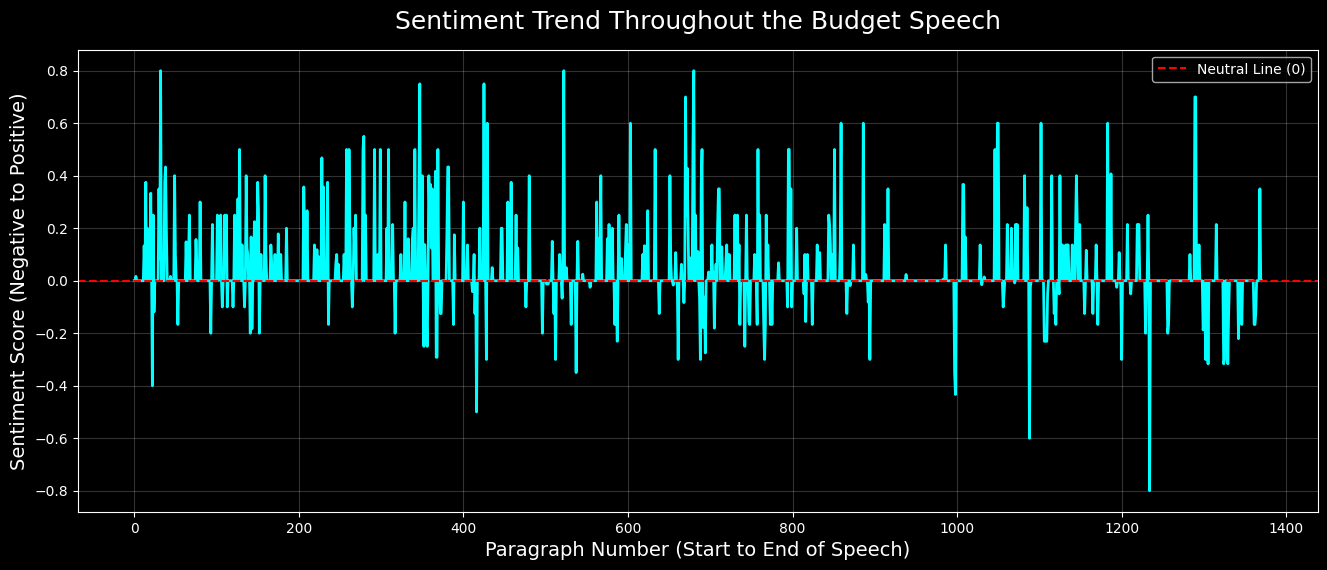

Sentiment Analysis Results
---------------------------------------------
Overall Tone: NEUTRAL (Factual/Balanced) | Score: 0.030


In [19]:
plt.figure(figsize=(16, 6))
plt.plot(df_sentiments['Polarity'], color='cyan', linewidth=2)
plt.axhline(y=0, color='red', linestyle='--', linewidth=1.5, label='Neutral Line (0)')
plt.title("Sentiment Trend Throughout the Budget Speech", fontsize=18, pad=15)
plt.xlabel("Paragraph Number (Start to End of Speech)", fontsize=14)
plt.ylabel("Sentiment Score (Negative to Positive)", fontsize=14)
plt.legend()
plt.grid(alpha=0.2)
plt.style.use('dark_background')
plt.show()


print('Sentiment Analysis Results')
print("-"*45)
if avg_sentiment > 0.05:
        print(f"Overall Tone: POSITIVE (Optimistic & Growth-oriented) | Score: {avg_sentiment:.3f}")
elif avg_sentiment < -0.05:
    print(f"Overall Tone: CAUTIOUS / NEGATIVE | Score: {avg_sentiment:.3f}")
else:
    print(f"Overall Tone: NEUTRAL (Factual/Balanced) | Score: {avg_sentiment:.3f}")

In [20]:
desc_stats = df_sentiments[['Polarity']].describe().T.round(3)

desc_stats.columns = ['Total Paragraphs', 'Average (Mean)', 'Std Dev', 'Minimum', '25%', 'Median', '75%', 'Maximum']
desc_stats.index = ['Sentiment Tone']

desc_stats

,Total Paragraphs,Average (Mean),Std Dev,Minimum,25%,Median,75%,Maximum
Sentiment Tone,1371.0,0.03,0.139,-0.8,0.0,0.0,0.0,0.8


In [21]:
mp = len(df_sentiments)//2

hf1 = df_sentiments['Polarity'][:mp]
hf2 = df_sentiments['Polarity'][mp:]

print(f"First Half Average Sentiment: {hf1.mean():.3f}")
print(f"Second Half Average Sentiment: {hf2.mean():.3f}")


t_stat, pval = stats.ttest_ind(hf1, hf2)

print(f'''T-Test hypothesis 
Test Statistic Value = {t_stat:.4f}
P Value = {pval:.4f}''')


if pval < 0.05:

    print("\nConclusion: P-value is lower 0.05 threshold.")
    print("This refers to that we have a significant difference between tone of first half and second half")
else:
    print("\nConclusion: P-value is higher than 0.05 threshold.")
    print("This refers to that we don't have a significant difference between tone of first half and second half")



First Half Average Sentiment: 0.046
Second Half Average Sentiment: 0.015
T-Test hypothesis 
Test Statistic Value = 4.1493
P Value = 0.0000

Conclusion: P-value is lower 0.05 threshold.
This refers to that we have a significant difference between tone of first half and second half


In [22]:
from IPython.display import display, Markdown

def model_eval(model, text_data):

    print(f"{model.upper()} is analyzing the budget......")

    # Aapka exact same prompt, maine isme 1 word bhi change nahi kiya hai
    prompt =f"""You are a highly skilled Economic Analyst and Data Scientist analyzing the Indian Union Budget Speech. 

Based strictly on the provided budget speech text, I need a comprehensive, structured, and highly detailed analysis broken down into the following three specific sections:

### 1. Sector-Wise Allocations & Focus
Provide a detailed breakdown of what specific announcements, funds, or policies were made for the following 10 sectors. (If a sector was not significantly mentioned, state "Limited mentions"):
- Agriculture & Farmers
- Education & Skills
- Health & Wellness
- Railways & Transport
- Technology & AI
- Defence & Security
- Women / Nari Shakti
- Youth & Employment
- Startups & MSME
- Infrastructure

### 2. The 'Rupee Comes From' Analysis (Revenue)
Explain the government's revenue model. If the government earns 100 Rupees, break down exactly where this money is coming from (e.g., Corporate Tax, Income Tax, GST, Borrowings, Non-tax revenue, etc.). Provide the exact percentages or paise breakdown if mentioned in the text.

### 3. The 'Rupee Goes To' Analysis (Expenditure)
Explain the government's expenditure model. If the government spends 100 Rupees, break down exactly where it is going (e.g., Interest Payments, Defence, Subsidies, State shares, Pensions, Central Sector Schemes, etc.). Provide the exact percentages or paise breakdown if mentioned in the text.

Format your response clearly using Markdown, bold text for key numbers, and bullet points. Do not hallucinate; use only the data present in the text provided below.

---
BUDGET SPEECH TEXT:
{text_data}
"""
    
    try:
        response = ollama.chat(model=model, messages=[{'role' : "user", "content" :prompt}])
        print(f'\n {model.upper()} Budget Analysis')
        print("=" * 60)
        
        # YAHAN CHANGE KIYA HAI: print() hata diya, aur display(Markdown()) laga diya
        # Issey Output scrollable nahi aayega, balki professional formatted aayega
        display(Markdown(response['message']['content']))
        
        print("=" * 60 + "\n")

    except Exception as e:
        print("ERROR with Ollama Models therefore Kindly Check Again..............")

In [23]:
budget_doc = " ".join(li)
model_eval('phi3', budget_doc )

PHI3 is analyzing the budget......

 PHI3 Budget Analysis



The given document outlines a comprehensive set of proposed amendments to the Income-Tax Act, 1961, by the Indian Government, aimed at simplifying the tax system, increasing the tax base, and promoting ease of doing business in India. The proposed changes cover various aspects such as direct taxes, capital gains, tax deductions, and other related matters. Here's a detailed summary of the key proposals:

Direct Taxes:
1. Substantial relief is proposed under the new tax regime with new slabs and tax rates as follows:
   - From ₹ 3,00,001 to ₹ 7,00,000, a 5% tax rate.
   - From ₹ 7,00,001 to ₹ 10,00,000, a 10% tax rate.
   - From ₹ 10,00,001 to ₹ 12,00,000, a 15% tax rate.
   - Above ₹ 12,00,000, a 20% tax rate.
2. Standard deduction for salaried individuals and pensioners is proposed to be increased from ₹ 50,000 to ₹ 75,000 under the new tax regime.
3. Family pension deduction from ₹ 15,000 is proposed to be increased to ₹ 25,000 under the new tax regime.
4. Non-government employer contributions to the New Pension scheme will have an increased deduction allowed, from 10% to 14% of the salary of the employee.
5. Income tax of foreign companies (other than those chargeable at special rates) will be reduced from 40% to 35%.
6. The provisions of clause (viib) of sub-section (2) of section 56 of the Act related to tax on share premium of private companies will not apply from the financial year 2024-25.

Measures to Promote Investment and Employment:
1. Retail schemes and Exchange Traded Funds in IFSC will enjoy tax exemptions.
2. Certain income of Core Settlement Guarantee Fund set up in IFSC will be exempt.
3. A VCF located in IFSC will not be called upon to explain the source of funds if it extends a loan or other amount to an assessee.

Simplification and Rationalisation:
1. Introduction of block assessment scheme for search and seizure cases with a proposed block period of six years and the period up to the date of conclusion of search, taxed at a rate of 60%.
2. Reducing the time limit for reassessment from ten years to five years and rationalising the procedure for reassessment.
3. Merge and rationalize the schemes for exemption of charitable trusts/institutions.
4. Simplify and rationalize the taxation of capital gains, with a tax rate of 20% on short-term gains and 12.5% on long-term gains.
5. Increase the limit of remuneration to working partners allowed as a deduction from ₹ 50,000 to ₹ 3,00,000 or 90% of the book profit, whichever is more, for the first ` 6,00,000 of the book-profit or in case of a loss.
6. Proposal for a presumptive taxation regime for cruise ship operations by non-residents.

Rationalisation of TDS and TCS:
1. TDS rates are proposed to be lowered in certain sections and omitted in section 194F.
2. Credit of TDS and TCS is proposed to be allowed in certain sections.
3. Claiming credit for TCS of minor in the hands of the parent is proposed.
4. Several amendments are proposed for the payment of insurance commission, rent by Section 194D, commission by Section 194G, rent by Section 194M, and certain sums by Section 194O and UFIs.
5. Surcharge on interest payable on securities will not apply.

Widening and Deepening of Tax Base and Anti-Avoidance:
1. Buy-back of shares by companies to be chargeable in the hands of the recipient investor as dividend with treatment as a capital loss.
2. Proposal to increase STT on sale of an option in securities and on sale of a futures in securities.
3. Income from letting out of a house property to be taxed under 'income from house property' and not 'profits and gains of business or profession'.
4. Transfer of a capital asset by an entity other than an individual or HUF to be considered a transfer for the purpose of capital gains calculation.
5. TDS on payments to partners for salary, remuneration, commission, bonus, and interest exceeding ₹ 20,000.
6. A proposal for TCS on luxury goods of value exceeding ₹ 10 lakh.
7. Clarification regarding transfer of immovable property with more than one transferor or transferee.
8. TDS on interest exceeding ₹ 10,000 on FRSB 2020 or any other notified security.
9. Proposal to include income taxes withheld outside India in the calculation of total income.
10. Exclusion of income mentioned in section 194J from applicability of section 194C.
11. Claim of settlement amounts as business expenditure is proposed to be disallowed.
12. A definition of Fair Market Value (FMV) is proposed for unlisted equity shares in an offer for sale in an initial public offer.

Additional measures:
1. Introduction of Vivad se Vishwas Scheme, 2024 for settlement of pending appeals.
2. Equalisation Levy exemption on e-commerce supply of goods or services at a 2% rate.
3. Decriminalization of late payment of TDS if paid before the time prescribed for filing the TDS statement.
4. Lower deduction or collection certificate of tax for section 194Q and sub-section 1H of section 206C.
5. Notification of persons or class of persons exempt from TCS for specified transactions.
6. A penalty for late furnishing of TDS or TCS statement beyond one month.
7. A six-year limit for filing annual statements of a liaison office.
8. A six-year limit for issuing correction statements for TDS/TCS statements.
9. A penalty for non-submission of annual statements.
10. Empowering the Transfer Pricing Officer for specified domestic transactions.
11. Discontinuation of quoting Aadhaar Enrolment ID in place of Aadhaar number.
12. Withdrawal of schemes for processing of statements before the Board for Advance Rulings.

Other Amendments:
1. Amendment in Section 271FAA to include a penalty for non-compliance with due diligence requirement relating to AEOI.
2. Inclusion of Black Money Act, 2015 for obtaining a tax clearance certificate.
3. Proposal to include income tax paid outside India as deemed income for computing total income.
4. Penalty for non-compliance with Black Money Act, 2015 provisions.
5. Adjusting liability under Black Money Act, 2015 against seized assets.
6. Amendments to the Prohibition of Benami Property Transactions Act, 1988 to provide immunity on full and true disclosure and rationalize time limits for attachment of property and reference to adjudicating authority.
7. Penalty for non-reporting of movable assets up to ₹ 20 lakh.

These proposals aim to simplify the tax system, promote ease of doing business, and improve tax compliance in India. The document is open for public consultation, and the government will likely finalize these changes based on the feedback received.

In [24]:
budget_doc = " ".join(li)
model_eval('llama3.1', budget_doc )

LLAMA3.1 is analyzing the budget......

 LLAMA3.1 Budget Analysis


This text appears to be a comprehensive summary of the key changes and proposals in the Indian Budget for 2024, specifically in the areas of Customs Duty, Direct Taxes, and Trade Facilitation Measures. The summary covers a wide range of topics, including:

1.  Customs Duty:
	* Increases in customs duty on various goods, such as Ammonium Nitrate, PVC Flex Films/Flex Banners, Laboratory Chemicals, and others.
	* Rationalization of export duty on Raw hides, skins, and leather.
	* Increase in duration for re-import of goods exported out of India.
	* Increase in duration for export of articles of foreign origin imported for repairs.
2. Direct Taxes:
	* Introduction of a new tax regime with new slabs and tax rates.
	* Standard deduction for salaried individuals and pensioners increased from ` 50,000 to ` 75,000.
	* Deduction for family pension increased from ` 15,000 to ` 25,000.
	* Increase in limit of remuneration to working partners of a firm.
	* Reduction of rate of income-tax chargeable on income of foreign companies from 40% to 35%.
	* Exemption from tax on share premium of private companies.
	* Presumptive taxation regime for cruise ship operations by non-residents.
3. Trade Facilitation Measures:
	* Increase in duration for re-import of goods exported out of India.
	* Increase in duration for export of articles of foreign origin imported for repairs.
	* Simplification of taxation of Capital Gains.
	* Rationalization of tax deducted at source (TDS) rates.
	* Credit of TDC and TCS.
	* Claiming credit for TCS of minor in the hands of parent.
4. Other Changes:
	* Introduction of Vivad se Vishwas Scheme, 2024.
	* Equalisation Levy.
	* Decriminalization of late payment of tax deducted at source (TDS).
	* Lower deduction/collection certificate of tax at source.
	* Notification of certain persons or class of persons as exempt from TCS.
	* Time limit to file correction statement for TDS/TCS statements.
	* Penalty for failure to furnish statements.
	* Prescription of period within which annual statement of activities of a liaison office is required to be furnished.

The summary provides a comprehensive overview of the key changes and proposals in the Indian Budget for 2024, covering a wide range of topics related to customs duty, direct taxes, and trade facilitation measures.

In [25]:
budget_doc = " ".join(li)
model_eval('qwen2', budget_doc )

QWEN2 is analyzing the budget......

 QWEN2 Budget Analysis


Based on the document provided, here is a summary of key proposals in the Indian Budget 2024:

1. **Excise Duty and Tariff Changes**: Several excise duties were increased or decreased for different products (e.g., ammonium nitrate, PVC flex films, solar glass, etc.), and tariffs were adjusted on imports and exports.

2. **Customs Duty Changes**: Customs duty was increased on certain capital goods used in manufacturing solar cells and warships, and on specific goods like cellular mobile phones and their components.

3. **Customs Duty Rationalization**: Customs duty on wet blue chrome leather was reduced from 40% to 20%, and E.I. tanned leather was exempt from customs duty. Finished leather (as defined by DGFT) remains without customs duty.

4. **Tax Rates and Slabs**: New tax rates and slabs were introduced for income tax under the new tax regime, with different rates applicable based on income brackets.

5. **Standard Deduction**: The standard deduction for salaried individuals and pensioners was increased from Rs. 50,000 to Rs. 75,000.

6. **Non-Government Employee Contributions**: The deduction allowed for contributions to the New Pension Scheme was increased from 10% to 14% of employee salary.

7. **Tax Exemptions for Foreign Entities**: Foreign companies would see their tax rate reduced from 40% to 35% and the tax on share premium abolished from financial year 2024-25.

8. **New Tax Regime for Non-Resident Cruise Ship Operators**: A presumptive taxation regime was proposed for non-resident cruise ship operators.

9. **Simplification and Rationalization**: Simplified capital gains taxation, rationalization of tax deduction at source (TDS) rates, and other tax-related reforms were proposed.

10. **Anti-Avoidance Measures**: Buy-back of shares was made taxable for investors, and securities transaction tax rates were increased on options and futures.

11. **Other Measures**: Tax on letting out of house property was moved to the 'income from house property' category, and various other tax proposals were included to broaden the tax base.

This summary highlights key points in the Indian Budget 2024, covering both tax and trade policy reforms.

In [ ]:
def gemini_model_eval(text_data):
    print("⏳ GEMINI is analyzing the budget......\n")

    prompt = f"""You are a highly skilled Economic Analyst and Data Scientist analyzing the Indian Union Budget Speech. 
Based strictly on the provided budget speech text, I need a comprehensive, structured, and highly detailed analysis broken down into the following three specific sections. 

CRITICAL RULE: You MUST output all three sections as Markdown Tables. 
CRITICAL INSTRUCTION: Keep the analysis EXTREMELY CONCISE. Provide a MAXIMUM of 3 very short bullet points per sector. Do not repeat any points.

### 1. Sector-Wise Allocations & Focus
Create a Markdown Table with two columns: 'Sector' and 'Key Announcements/Allocations'. 
Analyze these 10 sectors: Agriculture & Farmers, Education & Skills, Health & Wellness, Railways & Transport, Technology & AI, Defence & Security, Women / Nari Shakti, Youth & Employment, Startups & MSME, Infrastructure. (If not mentioned, write 'Limited mentions').

### 2. The 'Rupee Comes From' Analysis (Revenue)
Create a Markdown Table with two columns: 'Revenue Source' and 'Details/Percentage'. (If exact numbers aren't there, summarize major tax sources).

### 3. The 'Rupee Goes To' Analysis (Expenditure)
Create a Markdown Table with two columns: 'Expenditure Area' and 'Details/Percentage'. (If exact numbers aren't there, summarize major spending areas).

Do not hallucinate; use only the data present in the text provided below.
---
BUDGET SPEECH TEXT:
{text_data}
"""
    
    try:
        client = genai.Client(api_key="") # API Key is removed due to security and privacy concerns 
        
        response = client.models.generate_content(
            model='gemini-3.5-flash',
            contents=prompt,
            config=types.GenerateContentConfig(
                temperature=0.2,
            )
        )
            
        print('🌟 GEMINI Budget Analysis 🌟')
        print("=" * 60)
        display(Markdown(response.text))
        print("=" * 60 + "\n")
        
    except Exception as e:
        print(f"❌ ERROR with GEMINI API: {e}")

In [28]:
gemini_model_eval(budget_doc)

⏳ GEMINI is analyzing the budget......

🌟 GEMINI Budget Analysis 🌟


### 1. Sector-Wise Allocations & Focus

| Sector | Key Announcements/Allocations |
| :--- | :--- |
| **Agriculture & Farmers** | • Provision of ₹1.52 lakh crore for agriculture and allied sectors.<br>• 109 high-yielding, climate-resilient crop varieties to be released; 1 crore farmers initiated into natural farming.<br>• Digital Public Infrastructure (DPI) to cover 6 crore farmers and their lands in 3 years. |
| **Education & Skills** | • Provision of ₹1.48 lakh crore for education, employment, and skilling.<br>• Upgradation of 1,000 Industrial Training Institutes (ITIs) in hub-and-spoke arrangements.<br>• Financial support for domestic higher education loans up to ₹10 lakh with 3% interest subvention e-vouchers. |
| **Health & Wellness** | • Full exemption of basic customs duties on 3 additional cancer medicines.<br>• Customs duty rationalization on X-ray tubes and flat panel detectors to foster domestic capacity.<br>• Setting up of new medical colleges and sports infrastructure in Bihar. |
| **Railways & Transport** | • Development of major road expressways and spurs in Bihar (Patna-Purnea, Buxar-Bhagalpur, Bodhgaya-Darbhanga) at ₹26,000 crore.<br>• Infrastructure funding for industrial nodes along Vishakhapatnam-Chennai and Hyderabad-Bengaluru corridors (including railways).<br>• Reforms in ownership, leasing, and flagging for the Indian shipping and domestic cruise tourism industry. |
| **Technology & AI** | • Development of population-scale Digital Public Infrastructure (DPI) applications for credit, e-commerce, health, law, and MSMEs.<br>• Setting up an Integrated Technology Platform for the Insolvency and Bankruptcy Code (IBC) ecosystem.<br>• Basic customs duty on PCBA of specified telecom equipment increased from 10% to 15% to boost domestic manufacturing. |
| **Defence & Security** | • Created new tariff lines for defence products to align with World Customs Organization (WCO) standards.<br>• Duty exemptions on components/consumables for manufacturing vessels and aircraft for defence and coast guard.<br>• Customs exemptions extended to technical documentation and spare parts for warship construction. |
| **Women / Nari Shakti** | • Allocation of over ₹3 lakh crore for schemes benefitting women and girls.<br>• Setting up of working women hostels and crèches in collaboration with industry.<br>• Encouraging states to lower property stamp duties for purchases made by women. |
| **Youth & Employment** | • Prime Minister’s package of 5 schemes for 4.1 crore youth over 5 years with a central outlay of ₹2 lakh crore.<br>• Implementation of 3 Employment Linked Incentive schemes based on EPFO enrolment.<br>• Internship scheme in 500 top companies for 1 crore youth over 5 years with a ₹5,000 monthly allowance. |
| **Startups & MSME** | • Total abolition of Angel Tax for all classes of investors to foster the startup ecosystem.<br>• Credit guarantee scheme providing up to ₹100 crore cover for MSMEs purchasing machinery/equipment.<br>• Enhancement of Mudra loan limit to ₹20 lakh under the 'Tarun' category for past successful borrowers. |
| **Infrastructure** | • Capital expenditure provision of ₹11,11,111 crore (3.4% of GDP).<br>• Provision of ₹1.5 lakh crore in long-term interest-free loans to states for capital investment.<br>• Development of 12 industrial parks and plug-and-play industrial parks in/near 100 cities. |

---

### 2. The 'Rupee Comes From' Analysis (Revenue)

| Revenue Source | Details/Percentage |
| :--- | :--- |
| **Total Non-Borrowing Receipts** | Estimated at ₹32.07 lakh crore for FY 2024-25. |
| **Net Tax Receipts** | Estimated at ₹25.83 lakh crore. |
| **Gross & Net Market Borrowings** | Gross market borrowings estimated at ₹14.01 lakh crore; Net market borrowings at ₹11.63 lakh crore. |
| **Direct Taxes (Personal & Corporate)** | Over 58% of corporate tax collected via simplified regime (FY23); Corporate tax rate on foreign companies reduced from 40% to 35%. Slabs rationalized under new personal tax regime. |
| **Indirect Taxes (GST & Customs)** | GST simplified and expanded; Customs duties rationalized (reduced on gold, silver to 6%, platinum to 6.4%, critical minerals, and mobile devices; increased on ammonium nitrate and PVC flex banners). |
| **Capital Gains & Financial Transaction Taxes** | Short-term capital gains on specified financial assets raised to 20%; Long-term capital gains tax set at 12.5%; Securities Transaction Tax (STT) on futures raised to 0.02% and options to 0.1%. Share buy-back income taxed as dividend. |

---

### 3. The 'Rupee Goes To' Analysis (Expenditure)

| Expenditure Area | Details/Percentage |
| :--- | :--- |
| **Total Expenditure** | Estimated at ₹48.21 lakh crore for FY 2024-25. |
| **Capital Expenditure (CapEx)** | ₹11,11,111 crore allocated (3.4% of GDP). |
| **PM's Package for Employment & Skilling** | ₹2 lakh crore central outlay over 5 years (targeting 4.1 crore youth). |
| **Education, Employment & Skilling (Annual)** | ₹1.48 lakh crore provision for FY 2024-25. |
| **Agriculture & Allied Sectors** | ₹1.52 lakh crore provision for FY 2024-25. |
| **Rural Development & Rural Infrastructure** | ₹2.66 lakh crore provision for FY 2024-25. |
| **Women & Girls Welfare Schemes** | Allocation of over ₹3 lakh crore. |
| **State Infrastructure & Reform Support** | ₹1.5 lakh crore provision in 50-year interest-free loans to states. |
| **Urban Housing (PM Awas Yojana Urban 2.0)** | Central assistance of ₹2.2 lakh crore over 5 years (within a total investment of ₹10 lakh crore). |
| **Irrigation, Power & Special State Support** | Over ₹58,900 crore committed for Bihar road, power, and flood mitigation projects; ₹15,000 crore financial support arranged for Andhra Pradesh capital development. |